# Assignment 3: Regression Assumptions and Diagnostics

**Course:** STA 6110 -- Linear and Non-Linear Models
**Student:** Gabriel Kinyanjui Kariuki
**Week:** Week 4 -- Assumptions of Linear Regression

Run every cell top to bottom (Restart & Run All), then screenshot each output
as you go -- the section headers below match the headings in the Word report,
so you can drop each screenshot straight into the matching section.


## 0. Setup -- Import Libraries

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Statsmodels: gives a full OLS summary table, the Breusch-Pagan test,
# and leverage/influence diagnostics in one place
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence

from sklearn.datasets import load_diabetes

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

## 1. Research Problem -- Load and Inspect the Data

Dataset: Efron, Hastie, Johnstone & Tibshirani (2004) Diabetes dataset
(n = 442 patients), loaded via `scikit-learn` in its original (unscaled) units.

- **Dependent variable (Y):** Disease Progression Score
- **Independent variable (X):** BMI (kg/m^2)


In [2]:
diabetes = load_diabetes(scaled=False, as_frame=True)
df = diabetes.frame[['bmi', 'target']].rename(columns={'bmi': 'BMI', 'target': 'Y'})

print("Shape:", df.shape)
df.describe()

Shape: (442, 2)


,BMI,Y
count,442.0000,442.0000
mean,26.3758,152.1335
std,4.4181,77.0930
min,18.0000,25.0000
25%,23.2000,87.0000
50%,25.7000,140.5000
75%,29.2750,211.5000
max,42.2000,346.0000


## 2. Model Output -- Fit the Simple Linear Regression

In [3]:
X = df['BMI']
Y = df['Y']

X_with_const = sm.add_constant(X)   # adds the intercept column
model = sm.OLS(Y, X_with_const).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     230.7
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           3.47e-42
Time:                        12:45:55   Log-Likelihood:                -2454.0
No. Observations:                 442   AIC:                             4912.
Df Residuals:                     440   BIC:                             4920.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -117.7734     18.019     -6.536      0.0

In [ ]:
# Quick-reference table
b0, b1 = model.params['const'], model.params['BMI']
print(f"Estimated equation:  Y_hat = {b0:.2f} + {b1:.2f} * BMI")
print(f"R-squared          : {model.rsquared:.4f}")
print(f"Slope t-statistic  : {model.tvalues['BMI']:.3f}")
print(f"Slope p-value      : {model.pvalues['BMI']:.3e}")

Estimated equation:  Y_hat = -117.77 + 10.23 * BMI
R-squared          : 0.3439
Slope t-statistic  : 15.187
Slope p-value      : 3.466e-42


## 3. Diagnostic Checks

### 3.1 Linearity -- Scatter Plot and Residuals vs. Fitted


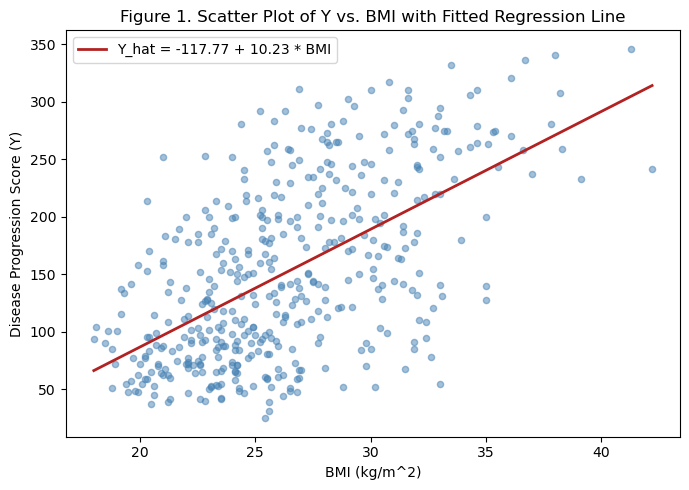

In [5]:
fitted = model.fittedvalues
resid = model.resid

# Figure 1: scatter plot with the fitted regression line
plt.figure(figsize=(7, 5))
plt.scatter(df['BMI'], df['Y'], alpha=0.5, s=20, color='steelblue')
x_line = np.linspace(df['BMI'].min(), df['BMI'].max(), 100)
plt.plot(x_line, b0 + b1 * x_line, color='firebrick', linewidth=2,
         label=f'Y_hat = {b0:.2f} + {b1:.2f} * BMI')
plt.xlabel('BMI (kg/m^2)')
plt.ylabel('Disease Progression Score (Y)')
plt.title('Figure 1. Scatter Plot of Y vs. BMI with Fitted Regression Line')
plt.legend()
plt.tight_layout()
plt.show()

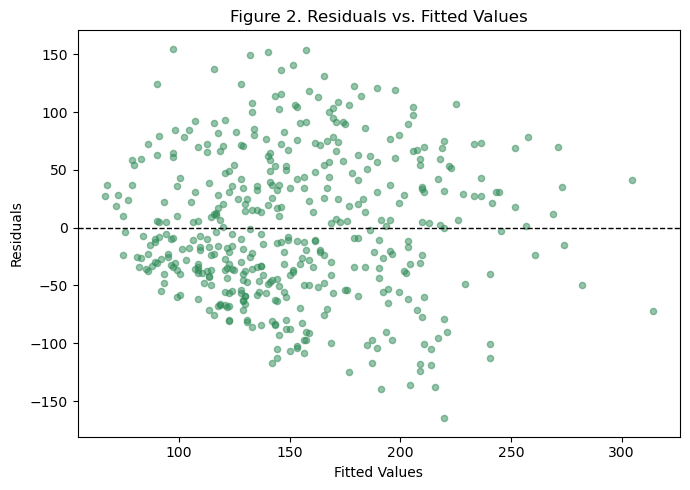

In [6]:
# Figure 2: residuals vs. fitted values (checks linearity)
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.5, s=20, color='seagreen')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Figure 2. Residuals vs. Fitted Values')
plt.tight_layout()
plt.show()

### 3.2 Homoscedasticity -- Scale-Location Plot and Breusch-Pagan Test

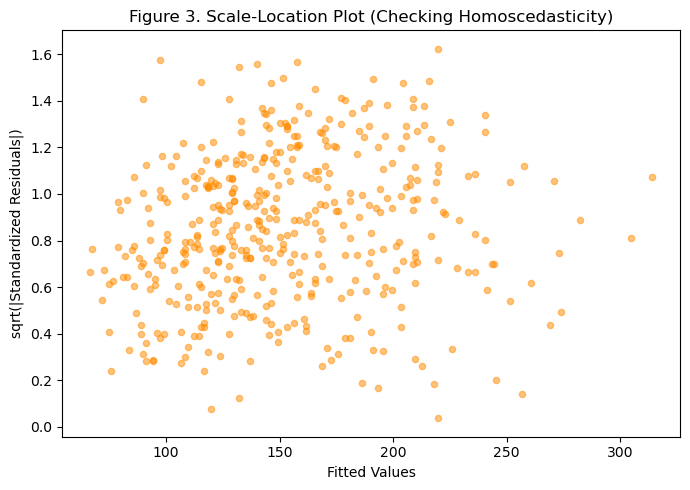

In [7]:
# Figure 3: scale-location plot
standardized_resid = resid / np.std(resid, ddof=2)
plt.figure(figsize=(7, 5))
plt.scatter(fitted, np.sqrt(np.abs(standardized_resid)), alpha=0.5, s=20, color='darkorange')
plt.xlabel('Fitted Values')
plt.ylabel('sqrt(|Standardized Residuals|)')
plt.title('Figure 3. Scale-Location Plot (Checking Homoscedasticity)')
plt.tight_layout()
plt.show()

In [8]:
# Formal test: Breusch-Pagan (H0 = homoscedasticity / constant variance)
bp_stat, bp_pvalue, bp_fstat, bp_fpvalue = het_breuschpagan(resid, X_with_const)
print(f"Breusch-Pagan LM statistic : {bp_stat:.4f}")
print(f"Breusch-Pagan p-value      : {bp_pvalue:.4f}")
print("--> p < 0.05 means the assumption of constant variance is violated.")

Breusch-Pagan LM statistic : 11.1213
Breusch-Pagan p-value      : 0.0009
--> p < 0.05 means the assumption of constant variance is violated.


### 3.3 Normality of Residuals -- Q-Q Plot and Shapiro-Wilk Test

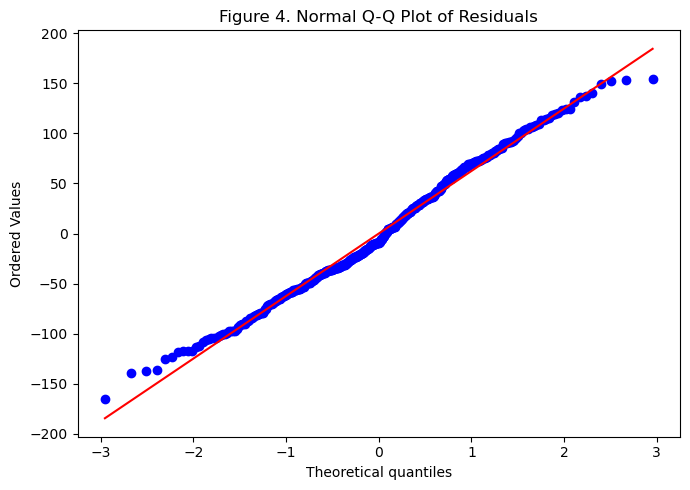

In [9]:
# Figure 4: normal Q-Q plot
plt.figure(figsize=(7, 5))
stats.probplot(resid, dist="norm", plot=plt)
plt.title('Figure 4. Normal Q-Q Plot of Residuals')
plt.tight_layout()
plt.show()

In [10]:
# Formal test: Shapiro-Wilk (H0 = residuals are normally distributed)
sw_stat, sw_pvalue = stats.shapiro(resid)
print(f"Shapiro-Wilk W : {sw_stat:.4f}")
print(f"p-value        : {sw_pvalue:.4f}")
print(f"Skewness       : {stats.skew(resid):.4f}")
print(f"Excess kurtosis: {stats.kurtosis(resid):.4f}")

Shapiro-Wilk W : 0.9904
p-value        : 0.0054
Skewness       : 0.1560
Excess kurtosis: -0.5474


## 4. Diagnostic Issue -- Leverage, Outliers, and Influence

Used to support the discussion of *which* diagnostic issue matters most
(Section 4 of the report) and to check for any single point distorting the fit.


In [11]:
influence = OLSInfluence(model)

leverage = influence.hat_matrix_diag
studentized_resid = influence.resid_studentized_external
cooks_d = influence.cooks_distance[0]

n, p = len(df), 2  # p = number of parameters (intercept + slope)
leverage_threshold = 2 * p / n
cooks_threshold = 4 / n

print(f"Leverage threshold (2p/n)      : {leverage_threshold:.4f}")
print(f"Points exceeding leverage      : {(leverage > leverage_threshold).sum()}")
print(f"Max leverage                   : {leverage.max():.4f} at BMI = {df['BMI'].iloc[leverage.argmax()]}")
print()
print(f"Max |studentized residual|     : {np.abs(studentized_resid).max():.4f}")
print(f"Points with |resid| > 3 (outlier flag): {(np.abs(studentized_resid) > 3).sum()}")
print()
print(f"Cook's Distance threshold (4/n): {cooks_threshold:.5f}")
print(f"Max Cook's Distance            : {cooks_d.max():.5f}")

Leverage threshold (2p/n)      : 0.0090
Points exceeding leverage      : 28
Max leverage                   : 0.0314 at BMI = 42.2

Max |studentized residual|     : 2.6662
Points with |resid| > 3 (outlier flag): 0

Cook's Distance threshold (4/n): 0.00905
Max Cook's Distance            : 0.02599


## 5. Recommended Remedy -- Robust (Heteroscedasticity-Consistent) Standard Errors

Since the heteroscedasticity detected above is statistically significant but
visually moderate, and the coefficients themselves are unbiased, the
proportionate fix is to re-report the model with **HC3 robust standard
errors** rather than transforming the outcome variable.


In [12]:
robust_model = sm.OLS(Y, X_with_const).fit(cov_type='HC3')
print(robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.344
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     274.1
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           3.34e-48
Time:                        12:46:12   Log-Likelihood:                -2454.0
No. Observations:                 442   AIC:                             4912.
Df Residuals:                     440   BIC:                             4920.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       -117.7734     15.941     -7.388      0.0

In [13]:
print("Comparison of standard errors:")
print(f"{'Parameter':<10}{'OLS SE':>12}{'Robust (HC3) SE':>20}")
for param in ['const', 'BMI']:
    print(f"{param:<10}{model.bse[param]:>12.4f}{robust_model.bse[param]:>20.4f}")

Comparison of standard errors:
Parameter       OLS SE     Robust (HC3) SE
const          18.0189             15.9409
BMI             0.6738              0.6181


## 6. Conclusion

Use the printed statistics above (R-squared, Breusch-Pagan p-value,
Shapiro-Wilk p-value, leverage/Cook's Distance results, and the OLS-vs-robust
standard error comparison) to support the written conclusion in the Word
report: the model is adequate for general explanation and cautious
prediction, linearity holds, normality is only mildly violated (tolerable at
n = 442 by the Central Limit Theorem), and the one real concern -- mild
heteroscedasticity -- is addressed by reporting robust standard errors
rather than re-specifying the model.
